# PROG8431 – Problem Analysis Workshop C
## Transformations and Linear Regression on the Predictive Maintenance Dataset

| Name | Student ID |
|---|---|
| Davisen Veerasamy | 8899632 |
| Carlos Gutierrez | 9118309 |
| Nnamdi Ikengah | 9085175 |

**Dataset:** The AI4I 2020 Predictive Maintenance Dataset (10,000 runs of a milling machine), plus the product-type specifications
and failure rules published with the dataset, plus the operating-zone clusters from our Workshop B.

**GitHub Repository:** [Group1-PROG8431-ProblemAnalysis_Workshop_C](https://github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_C)

**Contents**

1. Setup and Configuration
2. Load and Clean the Original Data
3. Add Data from Other Sources
4. Transform the Data (new variables)
5. Choose the Dependent Variable
6. Split into Training and Test Sets
7. Correlations
8. Simple Linear Regression (two models)
9. Multiple Linear Regression
10. Final Summary

## 1. Setup and Configuration

Clone the repository using the above link:
```bash
git clone https://github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_C.git
```
Open a terminal and navigate to the root directory
```bash
cd ./"your path here"
```
Create a virtual environment and activate
```bash
python -m venv .venv

# Windows (PowerShell)
.\.venv\Scripts\Activate.ps1

# macOS / Linux
source .venv/bin/activate
```
Install all the required packages using the requirements.txt
```bash
python -m pip install -r requirements.txt
```
Requires **Python 3.14+** (see `pyproject.toml`). With uv you can run `uv sync` instead. Then select the `.venv` kernel and run each code block in order.

### Coding Set Up

We start by clearing old plots, output and variables so the notebook runs from a clean state.

In [2]:
# Clear plots
import matplotlib.pyplot as plt
plt.close('all')

# Clear console
from IPython.display import clear_output
clear_output()

# Clean workspace
%reset -f

### Import Necessary Packages

These are the same packages used in the MLR demo, plus `KMeans` from Workshop B and two statsmodels diagnostics:
`het_breuschpagan` (tests the equal-spread assumption) and `variance_inflation_factor` (measures collinearity).

In [3]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import urllib.request
import zipfile

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp, chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.cluster import KMeans

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Set up number displays
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", None)
np.set_printoptions(suppress=True)

## 2. Load and Clean the Original Data

Same steps as Workshops A and B, so all our notebooks use the same column names:

1. Download the dataset from UCI if it is not already in the `data` folder.
2. Rename the columns to simple snake_case names.
3. Check for missing values and duplicates.
4. Drop `udi` and `product_id` (ID numbers only).

In [4]:
# Define paths inside a 'data' directory
data_dir = "data"
os.makedirs(data_dir, exist_ok=True)

# UCI AI4I 2020 Predictive Maintenance dataset zip URL
dataset_url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
zip_path = os.path.join(data_dir, "predictive_maintenance.zip")
csv_path = os.path.join(data_dir, "predictive_maintenance.csv")

# Download and extract if not present
if not os.path.exists(csv_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(dataset_url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    os.replace(os.path.join(data_dir, "ai4i2020.csv"), csv_path)
    print(f"Dataset saved to: {csv_path}")

# Load raw dataset
df = pd.read_csv(csv_path)

# 1. Rename columns (same names as Workshops A and B).
#    A mapping (old name -> new name) cannot mislabel columns if the column order changes.
df = df.rename(columns={
    "UDI": "udi",
    "Product ID": "product_id",
    "Type": "type",
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure",
    "TWF": "tool_wear_failure",
    "HDF": "heat_dissipation_failure",
    "PWF": "power_failure",
    "OSF": "overstrain_failure",
    "RNF": "random_failure",
})

# 2. Check missing values & duplicates
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("udi runs 1..10000 in order:", (df["udi"] == np.arange(1, len(df) + 1)).all())   # needed for the timeline in Section 3

# 3. Drop ID columns
df_clean = df.drop(columns=['udi', 'product_id']).copy()

print("\nShape:", df_clean.shape)
display(df_clean.head())

Missing Values: 0
Duplicates: 0
udi runs 1..10000 in order: True

Shape: (10000, 12)


,type,air_temp,process_temp,rotational_speed,torque,tool_wear,machine_failure,tool_wear_failure,heat_dissipation_failure,power_failure,overstrain_failure,random_failure
0,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0
3,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0
4,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0


The original file gives us **12 usable variables** (1 categorical, 5 sensor readings, 6 failure columns).
The assignment needs **at least 25**, so the next two sections add data from other sources and create new variables.

## 3. Add Data from Other Sources

### Source 1: Product type specifications (from the dataset documentation)

The people who made the AI4I dataset published how each product quality type (L / M / H) behaves.
This is in the dataset description on the UCI Machine Learning Repository and in the paper that introduced the data
(Matzka, 2020, *Explainable Artificial Intelligence for Predictive Maintenance Applications*). We typed this information
into a small table, `data/product_type_specs.csv`:

| Column | Meaning |
|---|---|
| `quality_label` | Low / Medium / High |
| `quality_rank` | 1 / 2 / 3 – an ordered number for the quality level |
| `tool_wear_added_min` | Minutes of tool wear each process adds (L = 2, M = 3, H = 5) |
| `osf_threshold_minNm` | The overstrain limit: if *tool wear × torque* goes above this, the tool fails (L = 11,000, M = 12,000, H = 13,000) |

**Why this source?** It is the official description of how the machine works, so it is the most reliable extra information
we can get for this data. It also lets us turn the product type into real numbers (like the overstrain limit), not just a letter.

We **merge** it onto our data using the `type` column (a left join, so every one of the 10,000 runs keeps its row).

In [5]:
specs = pd.read_csv("data/product_type_specs.csv")
display(specs)

# Merge on product type (left join keeps all 10,000 runs).
# validate="many_to_one" raises an error if a type appears twice in the specs table.
rows_before = len(df_clean)
df_clean = df_clean.merge(
    specs.drop(columns=["source"]),
    on="type",
    how="left",
    validate="many_to_one"
)
assert len(df_clean) == rows_before, "Merge changed the number of rows!"

print("Shape after merge:", df_clean.shape)
print("Missing values after merge:", df_clean.isnull().sum().sum())
display(df_clean.head())

,type,quality_label,quality_rank,tool_wear_added_min,osf_threshold_minNm,source
0,L,Low,1,2,11000,AI4I 2020 dataset description (UCI ML Reposito...
1,M,Medium,2,3,12000,AI4I 2020 dataset description (UCI ML Reposito...
2,H,High,3,5,13000,AI4I 2020 dataset description (UCI ML Reposito...


Shape after merge: (10000, 16)
Missing values after merge: 0


,type,air_temp,process_temp,rotational_speed,torque,tool_wear,machine_failure,tool_wear_failure,heat_dissipation_failure,power_failure,overstrain_failure,random_failure,quality_label,quality_rank,tool_wear_added_min,osf_threshold_minNm
0,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0,Medium,2,3,12000
1,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0,Low,1,2,11000
2,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0,Low,1,2,11000
3,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0,Low,1,2,11000
4,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0,Low,1,2,11000


### Source 2: Failure rules (from the dataset documentation)

The same documentation explains the exact rule behind each failure type:

| Failure | Rule from the documentation |
|---|---|
| Heat dissipation (HDF) | process temp − air temp **< 8.6 K** *and* rotational speed **< 1380 rpm** |
| Power (PWF) | power (torque × speed in rad/s) **< 3,500 W** or **> 9,000 W** |
| Overstrain (OSF) | tool wear × torque **>** the limit for the product type (11,000 / 12,000 / 13,000 minNm) |
| Tool wear (TWF) | the tool fails or is replaced somewhere between **200 and 240 minutes** of wear |
| Random (RNF) | 0.1% chance on any run |

We save these numbers as constants. Before using them, we **check that they really match our data** – if they recreate
the failure flags exactly, we know the source is trustworthy.

In [6]:
# Failure rule thresholds from the dataset documentation
HDF_TEMP_DIFF_MAX = 8.6     # K
HDF_SPEED_MAX = 1380        # rpm
PWF_POWER_MIN = 3500        # W
PWF_POWER_MAX = 9000        # W
TWF_WEAR_MIN = 200          # min

# Quick check: do the rules recreate the failure flags in our data?
temp_diff_check = df_clean["process_temp"] - df_clean["air_temp"]
power_check = df_clean["torque"] * df_clean["rotational_speed"] * 2 * np.pi / 60
strain_check = df_clean["tool_wear"] * df_clean["torque"]

hdf_rule = (temp_diff_check < HDF_TEMP_DIFF_MAX) & (df_clean["rotational_speed"] < HDF_SPEED_MAX)
pwf_rule = (power_check < PWF_POWER_MIN) | (power_check > PWF_POWER_MAX)
osf_rule = strain_check > df_clean["osf_threshold_minNm"]

print("HDF rule matches the flag on", (hdf_rule == df_clean["heat_dissipation_failure"]).sum(), "of 10,000 runs")
print("PWF rule matches the flag on", (pwf_rule == df_clean["power_failure"]).sum(), "of 10,000 runs")
print("OSF rule matches the flag on", (osf_rule == df_clean["overstrain_failure"]).sum(), "of 10,000 runs")

HDF rule matches the flag on 10000 of 10,000 runs
PWF rule matches the flag on 10000 of 10,000 runs
OSF rule matches the flag on 10000 of 10,000 runs


All three rules match **10,000 out of 10,000** runs, so the documented values are correct for our data and we can safely use
them to build new variables. (We also checked every number in our specs table against the dataset page on the UCI website.)

### Source 3 (separate datasets): Ontario weather and electricity data

The AI4I data only describes the machine itself. A real plant also has **outside conditions** – the weather and the cost of
electricity – that a maintenance team would care about. We add three real public datasets:

| Dataset | Publisher | What we use | Link |
|---|---|---|---|
| Hourly weather, station KITCHENER/WATERLOO (Climate ID 6144239) | Environment and Climate Change Canada | outdoor temperature, dew point, humidity, precipitation, wind speed, station pressure | climate.weather.gc.ca |
| Hourly Ontario Energy Price (HOEP) | IESO (Independent Electricity System Operator) | wholesale electricity price ($/MWh) | reports-public.ieso.ca |
| Hourly Ontario Demand | IESO | total Ontario electricity demand (MW) | reports-public.ieso.ca |

**Why these sources?** They are official government / grid-operator data, free and hourly. Kitchener-Waterloo is a large
manufacturing area close to Conestoga College, so it is a realistic location for our milling machine. Electricity price matters
because the machine runs on power, and with a price we can estimate the **energy cost of each run**.

**The key assumption – how we join them:** AI4I has no date or time column, so there is no shared key. We make one stated assumption:

> **The 10,000 runs are in time order (by `udi`), one run per hour, starting 2024-01-01 00:00 (Eastern Standard Time).**

This is reasonable because the UCI documentation says air temperature was generated as a *random walk*, which is a time series,
so the row order is meant to be time order. With one run per hour the data covers **2024-01-01 to 2025-02-20**. Both Environment
Canada and IESO report in Eastern Standard Time (no daylight saving), so the hours line up exactly.

The files are downloaded the first time the notebook runs and saved in `data/external/`, so later runs work offline.

In [7]:
ext_dir = os.path.join("data", "external")
os.makedirs(ext_dir, exist_ok=True)

weather_path = os.path.join(ext_dir, "weather_kitchener_waterloo_hourly.csv")
price_path = os.path.join(ext_dir, "ieso_hoep_hourly.csv")
demand_path = os.path.join(ext_dir, "ieso_ontario_demand_hourly.csv")

# 1. Environment Canada hourly weather (one file per month)
if not os.path.exists(weather_path):
    print("Downloading Environment Canada weather...")
    months = pd.date_range("2024-01-01", "2025-02-01", freq="MS")
    frames = []
    for m in months:
        url = ("https://climate.weather.gc.ca/climate_data/bulk_data_e.html?format=csv"
               f"&stationID=48569&Year={m.year}&Month={m.month}&Day=1&timeframe=1&submit=Download+Data")
        frames.append(pd.read_csv(url, encoding="utf-8-sig"))
    pd.concat(frames).to_csv(weather_path, index=False)

# 2. IESO hourly price (HOEP) and 3. IESO hourly Ontario demand (one file per year)
if not os.path.exists(price_path):
    print("Downloading IESO price data...")
    frames = [pd.read_csv(f"https://reports-public.ieso.ca/public/PriceHOEPPredispOR/PUB_PriceHOEPPredispOR_{y}.csv",
                          skiprows=3) for y in [2024, 2025]]
    pd.concat(frames).to_csv(price_path, index=False)

if not os.path.exists(demand_path):
    print("Downloading IESO demand data...")
    frames = [pd.read_csv(f"https://reports-public.ieso.ca/public/Demand/PUB_Demand_{y}.csv",
                          skiprows=3) for y in [2024, 2025]]
    pd.concat(frames).to_csv(demand_path, index=False)

weather_raw = pd.read_csv(weather_path)
price_raw = pd.read_csv(price_path)
demand_raw = pd.read_csv(demand_path)

print("Weather rows:", len(weather_raw), "| Price rows:", len(price_raw), "| Demand rows:", len(demand_raw))
print("Weather station:", weather_raw["Station Name"].unique())

Weather rows: 10200 | Price rows: 11664 | Demand rows: 17543
Weather station: <StringArray>
['KITCHENER/WATERLOO']
Length: 1, dtype: str


#### Clean the external data

- **Weather:** keep the useful columns and give them simple names. A few hours are missing (mostly wind speed). Because weather
  changes smoothly from hour to hour, we fill the gaps with **linear interpolation** (the average of the hours before and after).
  We drop wind direction and visibility (many gaps, and visibility is capped at 16.1 km).
- **IESO:** the files use "Hour 1 to 24" (hour ending). We change this to a normal timestamp, so Hour 1 on a day = 00:00.

In [8]:
# Weather: rename and keep useful columns
weather = weather_raw.rename(columns={
    "Date/Time (LST)": "timestamp",
    "Temp (°C)": "outdoor_temp_c",
    "Dew Point Temp (°C)": "dew_point_c",
    "Rel Hum (%)": "rel_humidity",
    "Precip. Amount (mm)": "precip_mm",
    "Wind Spd (km/h)": "wind_speed_kmh",
    "Stn Press (kPa)": "station_pressure_kpa"
})
weather_cols = ["outdoor_temp_c", "dew_point_c", "rel_humidity", "precip_mm", "wind_speed_kmh", "station_pressure_kpa"]
weather = weather[["timestamp"] + weather_cols]
weather["timestamp"] = pd.to_datetime(weather["timestamp"])
weather = weather.sort_values("timestamp")      # interpolation needs the rows in time order

print("Missing weather values BEFORE filling:")
print(weather[weather_cols].isnull().sum())

# Fill small gaps using the hours before and after
weather[weather_cols] = weather[weather_cols].interpolate(method="linear", limit_direction="both")
print("\nMissing weather values AFTER filling:", weather[weather_cols].isnull().sum().sum())

# IESO: change "Hour 1-24" into a timestamp
price = price_raw[["Date", "Hour", "HOEP"]].copy()
price["timestamp"] = pd.to_datetime(price["Date"]) + pd.to_timedelta(price["Hour"] - 1, unit="h")
price = price[["timestamp", "HOEP"]].rename(columns={"HOEP": "hoep_price"})

demand = demand_raw[["Date", "Hour", "Ontario Demand"]].copy()
demand["timestamp"] = pd.to_datetime(demand["Date"]) + pd.to_timedelta(demand["Hour"] - 1, unit="h")
demand = demand[["timestamp", "Ontario Demand"]].rename(columns={"Ontario Demand": "ontario_demand_mw"})

# Each table must have exactly one row per hour, otherwise the merge would duplicate runs
for name, table in [("weather", weather), ("price", price), ("demand", demand)]:
    print(f"{name:8s} duplicate timestamps: {table['timestamp'].duplicated().sum()}")

print("\nMissing price values:", price["hoep_price"].isnull().sum(), "| Missing demand values:", demand["ontario_demand_mw"].isnull().sum())

Missing weather values BEFORE filling:
outdoor_temp_c           24
dew_point_c              33
rel_humidity             32
precip_mm                23
wind_speed_kmh          370
station_pressure_kpa     23
dtype: int64

Missing weather values AFTER filling: 0
weather  duplicate timestamps: 0
price    duplicate timestamps: 0
demand   duplicate timestamps: 0

Missing price values: 0 | Missing demand values: 0


#### Merge everything on the timestamp

In [9]:
# Our assumption: one run per hour, in udi order, starting 2024-01-01 00:00 (EST)
df_clean["timestamp"] = pd.date_range("2024-01-01 00:00", periods=len(df_clean), freq="h")
print("First run:", df_clean["timestamp"].min(), "| Last run:", df_clean["timestamp"].max())

# Left joins keep all 10,000 runs; validate="one_to_one" proves no run is duplicated
rows_before = len(df_clean)
for table in [weather, price, demand]:
    df_clean = df_clean.merge(table, on="timestamp", how="left", validate="one_to_one")
assert len(df_clean) == rows_before, "Merge changed the number of rows!"

print("Shape after merge:", df_clean.shape)
print("Missing values after merge:", df_clean.isnull().sum().sum())
display(df_clean[["timestamp", "air_temp", "torque"] + weather_cols + ["hoep_price", "ontario_demand_mw"]].head())

First run: 2024-01-01 00:00:00 | Last run: 2025-02-20 15:00:00
Shape after merge: (10000, 25)
Missing values after merge: 0


,timestamp,air_temp,torque,outdoor_temp_c,dew_point_c,rel_humidity,precip_mm,wind_speed_kmh,station_pressure_kpa,hoep_price,ontario_demand_mw
0,2024-01-01 00:00:00,298.100,42.800,-1.300,-1.700,97.000,0.800,13.000,97.660,46.420,14482
1,2024-01-01 01:00:00,298.200,46.300,-1.600,-2.300,95.000,0.500,13.000,97.680,35.850,14180
2,2024-01-01 02:00:00,298.100,49.400,-1.800,-2.900,92.000,0.200,15.000,97.740,27.730,13722
3,2024-01-01 03:00:00,298.200,39.500,-1.900,-3.200,91.000,0.000,11.000,97.790,19.340,13637
4,2024-01-01 04:00:00,298.200,40.000,-2.100,-3.500,90.000,0.000,9.000,97.800,20.230,13697


Every one of the 10,000 runs found a matching hour in all three datasets (no missing values after the merge). The merges were
validated as one-to-one and the row count is unchanged, so no run was lost or duplicated.

**Sanity check on our assumption:** if AI4I really came from a real plant in our timeline, its `air_temp` (the temperature
inside the plant) might follow the outdoor temperature a little. Let's look.

Correlation between AI4I air_temp and real outdoor temperature: 0.774


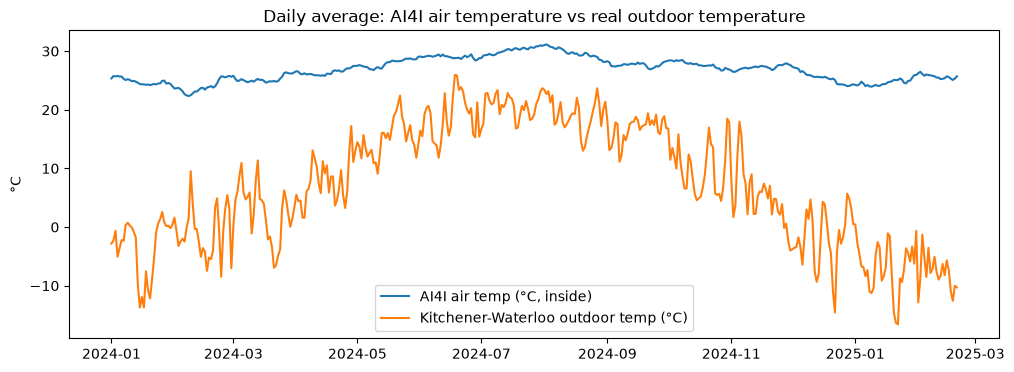

Correlation of day-to-day CHANGES: 0.002


In [10]:
print("Correlation between AI4I air_temp and real outdoor temperature:",
      round(df_clean["air_temp"].corr(df_clean["outdoor_temp_c"]), 3))

fig, ax1 = plt.subplots(figsize=(12, 4))
daily = df_clean.set_index("timestamp")[["air_temp", "outdoor_temp_c"]].resample("D").mean()
ax1.plot(daily.index, daily["air_temp"] - 273.15, label="AI4I air temp (°C, inside)")
ax1.plot(daily.index, daily["outdoor_temp_c"], label="Kitchener-Waterloo outdoor temp (°C)")
ax1.set_title("Daily average: AI4I air temperature vs real outdoor temperature")
ax1.set_ylabel("°C")
ax1.legend()
plt.show()

# Do the day-to-day CHANGES match as well?
daily_change = daily.diff().dropna()
print("Correlation of day-to-day CHANGES:",
      round(daily_change["air_temp"].corr(daily_change["outdoor_temp_c"]), 3))

**What we found – and why we have to be careful:**

- The correlation is about **0.77**, which looks strong. In the chart, AI4I's air temperature rises to a peak in the middle of the
  file and drops again, and in our timeline that middle falls in **summer**. So the overall shape fits a plant that gets warmer
  inside during summer, which supports our timeline.
- **But** the correlation of the **day-to-day changes** is about **0**. On a cold snap or heat wave outside, AI4I's temperature does
  not react at all. The match is only in the overall shape, not in the details.
- This is a classic trap with time data: **two series that both rise and fall slowly can look correlated by coincidence**
  (a *spurious correlation*). AI4I was generated by a simulation, not measured at a Kitchener plant, so we treat the 0.77 as a
  coincidence, not proof.
- **What it means for our models:** we expect the weather and electricity variables to have little or no real effect on torque.
  The regression in Section 9 will test this.

### Source 4: Operating-zone clusters from our Workshop B

In Workshop B we used K-Means on standardized rotational speed and torque (k = 4) and found four operating zones with very
different failure rates. We re-run the same clustering here (same settings) and add the zone as a new categorical variable.
The zone names are given by ordering the cluster centres from highest to lowest torque, so the names come out the same on
any computer.

In [11]:
# Same standardization and K-Means settings as Workshop B
def stamn(x):
    return (x - x.mean()) / x.std()

X_clust = pd.DataFrame({
    "speed_std": stamn(df_clean["rotational_speed"]),
    "torque_std": stamn(df_clean["torque"])
})

km = KMeans(n_clusters=4, max_iter=10, n_init=10, random_state=123)
km.fit(X_clust)

# Name the clusters by their torque centre (highest torque first)
torque_order = np.argsort(-km.cluster_centers_[:, 1])
zone_names = ["Slow & Heavy Load", "Normal Operation", "Moderate-Fast, Light Load", "Fast & Light Load"]
name_for_label = {label: zone_names[i] for i, label in enumerate(torque_order)}

df_clean["operating_zone"] = pd.Series(km.labels_).map(name_for_label)

print(df_clean["operating_zone"].value_counts())

operating_zone
Normal Operation             4161
Moderate-Fast, Light Load    2639
Slow & Heavy Load            2608
Fast & Light Load             592
Name: count, dtype: int64


The zone sizes (2,608 / 4,161 / 2,639 / 592) are the same as in Workshop B.

## 4. Transform the Data (new variables)

Now we use the extra information to create new variables. Each one has a reason:

| New variable | How it is made | Why |
|---|---|---|
| `temp_diff` | process_temp − air_temp | The heat-dissipation rule uses this difference |
| `power_w` | torque × speed × 2π / 60 | Power in watts; the power-failure rule uses it |
| `power_margin_w` | distance from power to the nearest safe limit (3,500 or 9,000 W) | Small or negative = close to a power failure |
| `strain_minNm` | tool_wear × torque | The overstrain rule uses this |
| `osf_margin_minNm` | osf_threshold − strain | How much "room" is left before an overstrain failure |
| `tool_uses` | tool_wear ÷ tool_wear_added_min | Roughly how many processes the tool has done |
| `log_speed` | log(rotational_speed) | Tukey's ladder (power 0) to reduce the skew in speed |
| `inv_speed` | 1000 ÷ rotational_speed | Tukey's ladder (power −1); physics says torque = power ÷ speed |
| `wear_stage` | tool_wear cut into New / Used / Old / End of life | Easier to read than minutes; End of life = 200+ min (the TWF zone) |
| `n_failure_modes` | sum of the 5 failure flags | Some runs fail in more than one way |
| `failure_type` | name of the failure mode (or "No Failure" / "Multiple") | One readable label instead of 5 columns |
| `hour`, `day_of_week`, `month` | taken from the timestamp | When the run happened |
| `is_weekend` | 1 = Saturday or Sunday | Weekend production may be different |
| `shift` | Day (07–15), Evening (15–23), Night (23–07) | Plants work in shifts; easier to use than 24 hours |
| `season` | Winter / Spring / Summer / Fall from the month | Groups the weather into seasons |
| `log_hoep` | log(1 + hoep_price) | Tukey's ladder (power 0): electricity price has huge spikes (very right-skewed) |
| `energy_kwh` | power_w × tool_wear_added_min ÷ 60 ÷ 1000 | Energy used by one process (assumes the cutting time = the minutes of tool wear it adds) |
| `energy_cost_cad` | energy_kwh × hoep_price ÷ 1000 | Electricity cost of one process in dollars (HOEP is $ per MWh) |

We also **convert all categorical variables** (`type`, `quality_label`, `wear_stage`, `failure_type`, `operating_zone`, `shift`, `season`)
to the `category` type, just like `Pension` in the MLR demo.

In [12]:
# Temperature difference
df_clean["temp_diff"] = df_clean["process_temp"] - df_clean["air_temp"]

# Power in watts (speed changed from rpm to rad/s)
df_clean["power_w"] = df_clean["torque"] * df_clean["rotational_speed"] * 2 * np.pi / 60

# Distance to the nearest power limit (negative = outside the safe range)
df_clean["power_margin_w"] = np.minimum(
    df_clean["power_w"] - PWF_POWER_MIN,
    PWF_POWER_MAX - df_clean["power_w"]
)

# Strain and room left before overstrain
df_clean["strain_minNm"] = df_clean["tool_wear"] * df_clean["torque"]
df_clean["osf_margin_minNm"] = df_clean["osf_threshold_minNm"] - df_clean["strain_minNm"]

# Approximate number of processes done by the tool
df_clean["tool_uses"] = df_clean["tool_wear"] / df_clean["tool_wear_added_min"]

# Tukey's ladder transformations of rotational speed
df_clean["log_speed"] = np.log(df_clean["rotational_speed"])
df_clean["inv_speed"] = 1000 / df_clean["rotational_speed"]

# Tool wear stage
df_clean["wear_stage"] = pd.cut(
    df_clean["tool_wear"],
    bins=[-1, 69, 139, TWF_WEAR_MIN - 1, 1000],
    labels=["New", "Used", "Old", "End of life"]
)

# Failure mode count and label
failure_flags = ["tool_wear_failure", "heat_dissipation_failure", "power_failure",
                 "overstrain_failure", "random_failure"]
flag_names = {
    "tool_wear_failure": "Tool Wear",
    "heat_dissipation_failure": "Heat Dissipation",
    "power_failure": "Power",
    "overstrain_failure": "Overstrain",
    "random_failure": "Random"
}

df_clean["n_failure_modes"] = df_clean[failure_flags].sum(axis=1)

def label_failure(row):
    if row["n_failure_modes"] == 0:
        return "No Failure"
    if row["n_failure_modes"] > 1:
        return "Multiple"
    for flag in failure_flags:
        if row[flag] == 1:
            return flag_names[flag]

df_clean["failure_type"] = df_clean.apply(label_failure, axis=1)

# Time variables from the timestamp
df_clean["hour"] = df_clean["timestamp"].dt.hour
df_clean["day_of_week"] = df_clean["timestamp"].dt.day_of_week      # 0 = Monday, 6 = Sunday
df_clean["month"] = df_clean["timestamp"].dt.month
df_clean["is_weekend"] = (df_clean["day_of_week"] >= 5).astype(int)

def get_shift(hour):
    if 7 <= hour < 15:
        return "Day"
    elif 15 <= hour < 23:
        return "Evening"
    else:
        return "Night"

df_clean["shift"] = df_clean["hour"].apply(get_shift)

season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer",
              9: "Fall", 10: "Fall", 11: "Fall"}
df_clean["season"] = df_clean["month"].map(season_map)

# Tukey's ladder (log) for the skewed electricity price; +1 because some prices are 0
df_clean["log_hoep"] = np.log(1 + df_clean["hoep_price"])

# Energy and cost of one process
df_clean["energy_kwh"] = df_clean["power_w"] * df_clean["tool_wear_added_min"] / 60 / 1000
df_clean["energy_cost_cad"] = df_clean["energy_kwh"] * df_clean["hoep_price"] / 1000

# Convert categorical variables
for col in ["type", "quality_label", "wear_stage", "failure_type", "operating_zone", "shift", "season"]:
    df_clean[col] = df_clean[col].astype("category")

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 46 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   type                      10000 non-null  category      
 1   air_temp                  10000 non-null  float64       
 2   process_temp              10000 non-null  float64       
 3   rotational_speed          10000 non-null  int64         
 4   torque                    10000 non-null  float64       
 5   tool_wear                 10000 non-null  int64         
 6   machine_failure           10000 non-null  int64         
 7   tool_wear_failure         10000 non-null  int64         
 8   heat_dissipation_failure  10000 non-null  int64         
 9   power_failure             10000 non-null  int64         
 10  overstrain_failure        10000 non-null  int64         
 11  random_failure            10000 non-null  int64         
 12  quality_label             1000

### Tukey's ladder: does transforming rotational speed help?

In our first assignment we found rotational speed is strongly **right-skewed** (skew ≈ 2.0). The lecture showed that Tukey's
ladder of powers can change the shape of a skewed variable. We compare the original, log (power 0) and reciprocal (power −1).

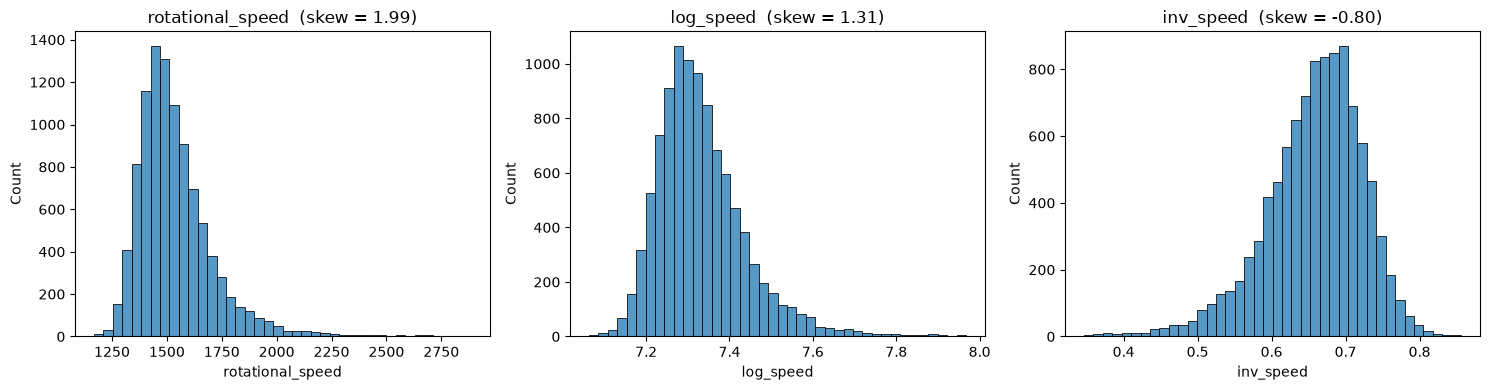

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["rotational_speed", "log_speed", "inv_speed"]):
    sns.histplot(df_clean[col], bins=40, ax=ax)
    ax.set_title(f"{col}  (skew = {df_clean[col].skew():.2f})")

plt.tight_layout()
plt.show()

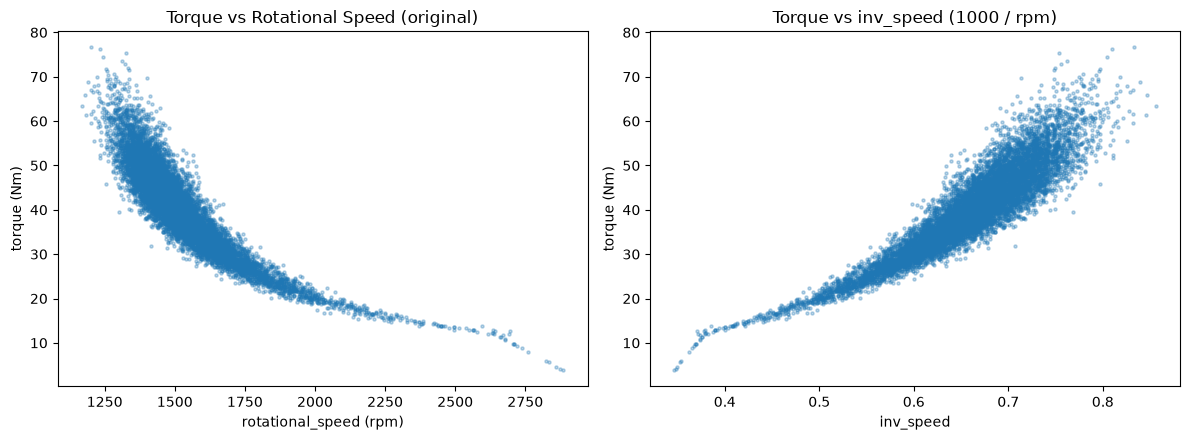

In [14]:
# How does torque relate to speed before and after the transformation?
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(df_clean["rotational_speed"], df_clean["torque"], s=5, alpha=0.3)
axes[0].set_title("Torque vs Rotational Speed (original)")
axes[0].set_xlabel("rotational_speed (rpm)")
axes[0].set_ylabel("torque (Nm)")

axes[1].scatter(df_clean["inv_speed"], df_clean["torque"], s=5, alpha=0.3)
axes[1].set_title("Torque vs inv_speed (1000 / rpm)")
axes[1].set_xlabel("inv_speed")
axes[1].set_ylabel("torque (Nm)")

plt.tight_layout()
plt.show()

**What we see:**

- **Skew:** the original speed has a skew of about **1.99**. The log brings it down to about **1.31**, and the reciprocal
  over-corrects a little to about **−0.80** (now slightly skewed the other way). As the lecture warned, the transformations do not make
  speed perfectly normal, but both reduce the skew.
- **Relationship with torque:** this is the bigger win. Against the original speed, the torque points form a **curve** (it bends and
  flattens out at high speed). Against `inv_speed` the points form a much **straighter line**. That makes sense from physics:
  power = torque × speed, so torque = power ÷ speed, and torque should be a straight line against 1 ÷ speed.
- Linear regression fits straight lines, so `inv_speed` should give a better model. We test this in Section 8.

The electricity price (HOEP) is also very skewed – most hours are cheap, but a few hours spike to over $1,000 per MWh.
We apply the same idea (log) to it.

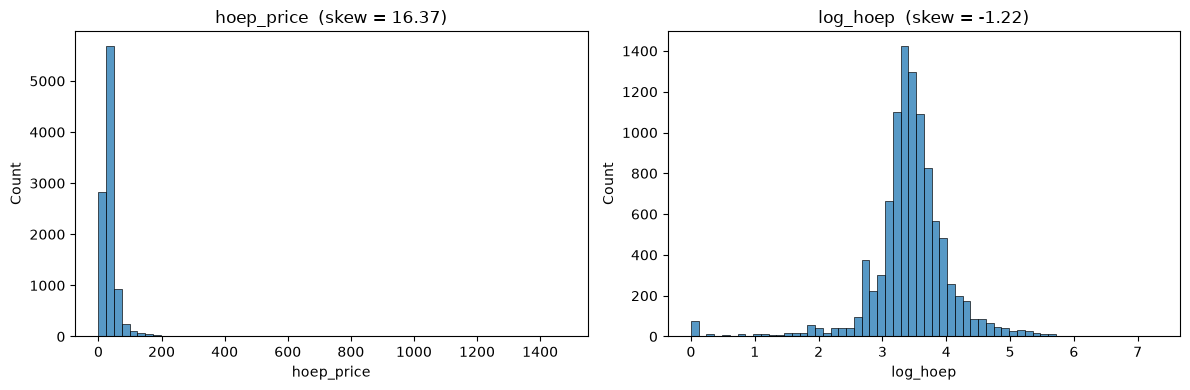

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean["hoep_price"], bins=60, ax=axes[0])
axes[0].set_title(f"hoep_price  (skew = {df_clean['hoep_price'].skew():.2f})")

sns.histplot(df_clean["log_hoep"], bins=60, ax=axes[1])
axes[1].set_title(f"log_hoep  (skew = {df_clean['log_hoep'].skew():.2f})")

plt.tight_layout()
plt.show()

**What we see:** the raw price has a skew of about **16.4** – most hours cost around $30 per MWh (median $30.15), but 68 hours are
above $200 and one reaches $1,476. After the log transformation the skew is about **−1.2**. It over-corrects a little, because 78 hours
had a price of exactly $0, but it is far less extreme, so a few spikes won't dominate a regression. We use `log_hoep` in the models.

**Energy cost:** with our energy variables, one process uses on average **0.27 kWh** and costs about **1 cent** at the wholesale price
(maximum about 80 cents during a price spike). Over all 10,000 runs that adds up to about **$101**.

### Final study file: variable count

In [16]:
# The timestamp is only used as a key to join the data, so we don't count it as a variable
print("Number of usable variables:", df_clean.shape[1] - 1, "(plus the timestamp key)")
print()

var_table = pd.DataFrame({
    "data_type": df_clean.dtypes.astype(str),
    "missing": df_clean.isnull().sum()
})
display(var_table)

# Save the final study file
df_clean.to_csv("data/study_file.csv", index=False)

Number of usable variables: 45 (plus the timestamp key)



,data_type,missing
type,category,0
air_temp,float64,0
process_temp,float64,0
rotational_speed,int64,0
torque,float64,0
tool_wear,int64,0
machine_failure,int64,0
tool_wear_failure,int64,0
heat_dissipation_failure,int64,0
power_failure,int64,0


**Data sources and transformations – summary**

- We started with **12 usable variables** from the AI4I dataset and now have **45**.
- **Sources added:** (1) product type specifications and (2) failure rules from the official dataset documentation,
  (3) three separate public datasets – Environment Canada hourly weather, IESO hourly electricity price and IESO hourly Ontario
  demand – joined on a timestamp, and (4) the operating-zone clusters from our Workshop B.
- **Why these sources:** the documentation describes exactly how the machine works (we proved this by recreating the HDF, PWF and
  OSF failure flags perfectly). The weather and electricity data add the real-world conditions around a plant, and let us estimate the
  energy cost of each run. The Workshop B zones carry forward our own earlier finding.
- **Main assumption:** one run per hour in `udi` order starting 2024-01-01. The sanity check showed AI4I's air temperature does not
  follow the real weather, so we expect the weather variables to have little effect on the machine readings.
- **Why these transformations:** most new variables are the physical quantities behind the failure rules (power, strain, margins),
  which are more meaningful than the raw readings. The log / reciprocal of speed are Tukey's ladder transformations for the skew and the
  curved relationship with torque. All categorical variables are converted to `category`.
- The final study file is saved as `data/study_file.csv`.

## 5. Choose the Dependent Variable

### Dependent variable: `torque` (Nm)

**Why torque?**

- In Workshop A and B torque was our **strongest warning sign**: failed runs had much higher torque (t-test), and the
  *Slow & Heavy Load* zone failed 10% of the time.
- Torque is **bell-shaped** (Shapiro-Wilk in Workshop A), which suits linear regression.
- **Business question:** *Can we estimate the expected torque (load) on the spindle from the other readings?* If the real torque
  is much higher than what the model expects, that is a sign something is wrong (anomaly detection, as described in the lecture).
  It could also act as a backup if the torque sensor fails.

**Important – variables we cannot use as predictors (data leakage):**

- **Calculated from torque:** `power_w`, `power_margin_w`, `strain_minNm`, `osf_margin_minNm`, `energy_kwh`, `energy_cost_cad`,
  and `operating_zone` (clustered on torque).
- **Defined by torque thresholds:** `power_failure` is just power outside 3,500–9,000 W, and `overstrain_failure` is just
  tool wear × torque above a limit. Our rule check in Section 3 recreated both on 10,000/10,000 runs. `machine_failure`,
  `n_failure_modes` and `failure_type` contain these flags.
- **Outcomes recorded after the run:** `tool_wear_failure`, `heat_dissipation_failure` and `random_failure` aren't defined by torque,
  but they're only known once a run has finished, so they couldn't be used to predict torque during a run.

Using these to predict torque would be cheating, because the answer is already hidden inside them. They stay in the study file for
other parts of our term project, but are left out of the regression models.


## 6. Split into Training and Test Sets

As in the class demo, we split the data **80% training / 20% test** with a fixed `random_state` so the split is the same every time.

- The **training set** (8,000 runs) is used to build the models.
- The **test set** (2,000 runs) is kept aside and only used to check how well the models work on data they have never seen.

80/20 is within the range from the lecture (training is typically 60–80%). Because we have 10,000 rows, 20% still gives a large
test set of 2,000 runs.

In [17]:
# Splitting with 80/20
train, test = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=6174
)

print("Train:", train.shape)
print("Test: ", test.shape)

Train: (8000, 46)
Test:  (2000, 46)


### Are the two sets comparable?

First we compare the summary statistics side by side.

In [18]:
compare_cols = ["air_temp", "process_temp", "rotational_speed", "torque", "tool_wear",
                "temp_diff", "inv_speed", "outdoor_temp_c", "rel_humidity", "hoep_price",
                "ontario_demand_mw", "machine_failure"]

summary_compare = pd.DataFrame({
    "train_mean": train[compare_cols].mean(),
    "test_mean": test[compare_cols].mean(),
    "train_std": train[compare_cols].std(),
    "test_std": test[compare_cols].std(),
    "train_min": train[compare_cols].min(),
    "test_min": test[compare_cols].min(),
    "train_max": train[compare_cols].max(),
    "test_max": test[compare_cols].max()
})

display(summary_compare)

,train_mean,test_mean,train_std,test_std,train_min,test_min,train_max,test_max
air_temp,300.017,299.957,2.002,1.993,295.300,295.300,304.500,304.300
process_temp,310.015,309.967,1.485,1.480,305.700,305.700,313.800,313.800
rotational_speed,1538.012,1541.834,178.740,181.457,1168.000,1192.000,2886.000,2874.000
torque,40.076,39.633,9.966,9.973,3.800,4.200,76.600,74.500
tool_wear,108.111,107.313,63.707,63.455,0.000,0.000,253.000,246.000
temp_diff,9.998,10.010,1.005,0.984,7.600,7.600,12.100,12.100
inv_speed,0.658,0.656,0.066,0.067,0.347,0.348,0.856,0.839
outdoor_temp_c,7.265,6.791,10.929,10.965,-21.100,-20.600,32.500,32.800
rel_humidity,78.707,79.486,16.862,16.154,22.000,29.000,100.000,100.000
hoep_price,37.143,36.728,41.887,31.550,0.000,0.000,1476.340,583.650


Then we use the **Kolmogorov-Smirnov (KS) test** for the numeric variables.

- H0: the training and test values come from the same distribution.
- If the p-value is **above 0.05**, we keep H0 and the sets are comparable for that variable.

In [19]:
# Comparing Numeric using Kolmogorov-Smirnov
numeric_vars = ["air_temp", "process_temp", "rotational_speed", "torque", "tool_wear",
                "temp_diff", "log_speed", "inv_speed", "tool_uses",
                "outdoor_temp_c", "dew_point_c", "rel_humidity", "precip_mm", "wind_speed_kmh",
                "station_pressure_kpa", "hoep_price", "log_hoep", "ontario_demand_mw", "energy_kwh"]

ks_rows = []
for var in numeric_vars:
    stat, p = ks_2samp(train[var], test[var])
    ks_rows.append({
        "Variable": var,
        "KS Statistic": round(stat, 4),
        "p-value": round(p, 4),
        "Same distribution?": "Yes" if p > 0.05 else "No"
    })

display(pd.DataFrame(ks_rows))

,Variable,KS Statistic,p-value,Same distribution?
0,air_temp,0.025,0.289,Yes
1,process_temp,0.021,0.447,Yes
2,rotational_speed,0.017,0.748,Yes
3,torque,0.022,0.425,Yes
4,tool_wear,0.015,0.833,Yes
5,temp_diff,0.016,0.811,Yes
6,log_speed,0.017,0.748,Yes
7,inv_speed,0.017,0.748,Yes
8,tool_uses,0.025,0.257,Yes
9,outdoor_temp_c,0.031,0.085,Yes


And the **Chi-square test** for the categorical variables.

- H0: the category proportions are the same in the training and test sets.

In [20]:
# Comparing Categorical with Chi-Square
cat_vars = ["type", "wear_stage", "operating_zone", "machine_failure", "failure_type",
            "shift", "season", "is_weekend"]

chi_rows = []
for var in cat_vars:
    trainp = train[var].value_counts().sort_index()
    testp = test[var].value_counts().sort_index()

    contingency_table = pd.DataFrame([trainp, testp], index=["Train", "Test"]).fillna(0)
    chi2, p, dof, expected = chi2_contingency(contingency_table)

    chi_rows.append({
        "Variable": var,
        "Chi-square": round(chi2, 4),
        "p-value": round(p, 4),
        "Min expected count": round(expected.min(), 1),   # chi-square needs about 5+ in every cell
        "Same proportions?": "Yes" if p > 0.05 else "No"
    })

display(pd.DataFrame(chi_rows))

# Failure counts in each set
print("Failures in train:", train["machine_failure"].sum(), f"({train['machine_failure'].mean()*100:.2f}%)")
print("Failures in test: ", test["machine_failure"].sum(), f"({test['machine_failure'].mean()*100:.2f}%)")

,Variable,Chi-square,p-value,Min expected count,Same proportions?
0,type,1.271,0.530,200.600,Yes
1,wear_stage,1.913,0.591,160.200,Yes
2,operating_zone,2.662,0.447,118.400,Yes
3,machine_failure,0.261,0.609,67.800,Yes
4,failure_type,3.054,0.802,3.600,Yes
5,shift,1.936,0.380,665.800,Yes
6,season,5.024,0.170,436.800,Yes
7,is_weekend,1.504,0.220,566.400,Yes


Failures in train: 267 (3.34%)
Failures in test:  72 (3.60%)


**Results of the split:**

- The training set has **8,000 runs** and the test set has **2,000 runs** (80/20).
- The **means, standard deviations and min/max values are very close** for every variable. For example, average torque is 40.08 Nm in
  training and 39.63 Nm in test, and the standard deviations are almost identical (9.97 vs 9.97).
- **KS test:** all 19 numeric variables have p-values above 0.05, so we keep H0. Training and test come from the same distribution.
- **Chi-square test:** all 8 categorical variables (including `shift`, `season` and `is_weekend`) have p-values above 0.05, so the
  category proportions are the same.

**Small dissimilarities we noticed:**

- The test set has a slightly higher failure rate (**3.60%** vs **3.34%**, i.e. 72 vs 267 failures). The chi-square test says this is
  not significant (p = 0.61), but with only 72 failures in the test set, a few extra failures can shift the result.
- `failure_type`: the chi-square test assumes every **expected** count is at least about 5. Its rarest types (Random, Multiple)
  give a minimum expected count of only **3.6**, so its p-value (0.80) is only approximate. The overall failure rate
  (`machine_failure`, minimum expected count 67.8) has plenty of counts and matches well.
- `outdoor_temp_c` (p = 0.085) and `rel_humidity` (p = 0.093) passed, but only just. The test set is slightly colder on average
  (6.8 °C vs 7.3 °C). It is still not significant, so we just note it.
- The **electricity price spikes** are mostly in the training set. Max HOEP is $1,476 in training vs $584 in test, and the standard
  deviation is 41.9 vs 31.6. The KS test still passes (p = 0.51) because the *typical* prices are the same, but the test set has no
  extreme price hours.
- The highest values in the test set are a bit lower (max torque 74.5 vs 76.6 Nm, max tool wear 246 vs 253 min). This is expected,
  because a smaller sample is less likely to include the most extreme runs.

**Conclusion:** the two sets are comparable, so the test set is a fair check of how the models do on new data.

## 7. Correlations (training set only)

We use **Spearman** correlation, because some variables are skewed (speed) and some are 0/1 flags.
We only use the training set here, so the test set stays "unseen".

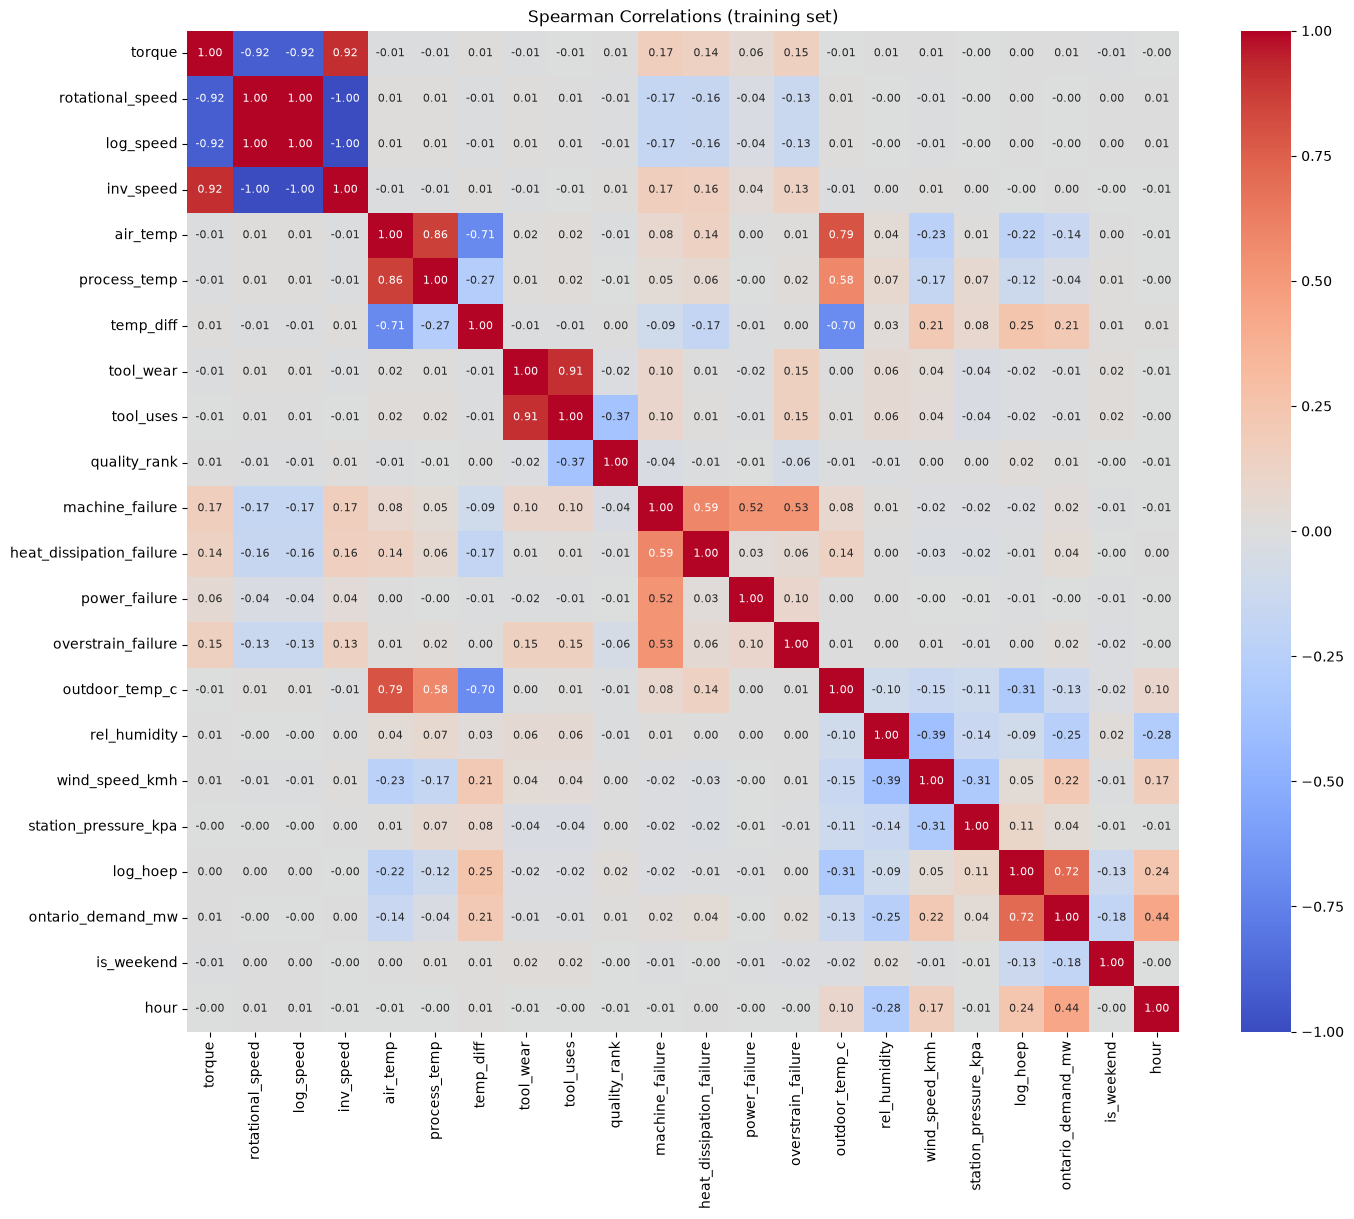

Correlation with torque (sorted):
rotational_speed           -0.916
inv_speed                   0.916
log_speed                  -0.916
machine_failure             0.171
overstrain_failure          0.153
heat_dissipation_failure    0.143
power_failure               0.059
air_temp                   -0.014
process_temp               -0.012
temp_diff                   0.012
is_weekend                 -0.010
tool_wear                  -0.008
ontario_demand_mw           0.007
outdoor_temp_c             -0.007
rel_humidity                0.007
wind_speed_kmh              0.007
tool_uses                  -0.005
quality_rank                0.005
log_hoep                    0.005
station_pressure_kpa       -0.002
hour                       -0.001
Name: torque, dtype: float64


In [21]:
corr_cols = ["torque", "rotational_speed", "log_speed", "inv_speed", "air_temp", "process_temp",
             "temp_diff", "tool_wear", "tool_uses", "quality_rank", "machine_failure",
             "heat_dissipation_failure", "power_failure", "overstrain_failure",
             "outdoor_temp_c", "rel_humidity", "wind_speed_kmh", "station_pressure_kpa",
             "log_hoep", "ontario_demand_mw", "is_weekend", "hour"]

corr_matrix = train[corr_cols].corr(method="spearman")

plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", annot_kws={"size": 8})
plt.title("Spearman Correlations (training set)")
plt.show()

print("Correlation with torque (sorted):")
print(corr_matrix["torque"].drop("torque").sort_values(key=abs, ascending=False).round(3))

**What the correlations tell us:**

- **Speed is by far the strongest predictor of torque** (Spearman ≈ **−0.92**, a strong relationship). The original, log and
  reciprocal versions all have the same Spearman value, because Spearman uses *ranks*, and the transformations keep the same order.
  (The ordinary Pearson correlation is −0.875 for the original speed and +0.915 for `inv_speed`, which shows the transformation helps
  a *linear* model.)
- The **failure flags** have weak positive correlations with torque (0.06 to 0.17). Failed runs, especially overstrain, have higher torque.
- **Temperatures, tool wear, tool uses and quality** have almost **no** correlation with torque (all below 0.02).
- **None of the new external variables** (outdoor temperature, humidity, wind, pressure, electricity price, Ontario demand, weekend,
  hour) are related to torque. All their correlations are below 0.011. This is what we expected after the sanity check: the outside
  conditions don't drive the machine readings in this data.
- In the full heatmap, `air_temp` and `outdoor_temp_c` correlate with each other (because of the shared summer hump), and so do the
  weather variables (temperature and dew point). That is another reason to expect collinearity in the full model.
- **Warning for MLR:** `rotational_speed`, `log_speed` and `inv_speed` are almost perfectly correlated with each other (≈ 1.00).
  Putting all three in one model will cause **collinearity**, which the lecture lists as a reason to choose variables carefully.

## 8. Simple Linear Regression (two models)

We build two SLR models on **two different independent variables** and compare them:

- **Model A: torque ~ rotational_speed**: the strongest candidate in the correlation matrix.
- **Model B: torque ~ tool_wear**: the obvious alternative. Does a more worn tool need more torque?

Then we **refine** the winner with Tukey's ladder (log and reciprocal of speed) to test our transformation.
(An earlier draft compared `rotational_speed` with `inv_speed`, but `inv_speed` is just 1000 ÷ the same variable, so it isn't a
*different* independent variable.)

For each model we check (as in the lecture):

1. **F-statistic and its p-value**: does the model explain anything at all?
2. **R² / Adjusted R²**: how much of the variation in torque is explained?
3. **t-test p-value of the coefficient**: is the slope different from 0?
4. **Coefficient**: do its sign and size make sense?
5. **RMSE on the training and the test set**: how far off are the predictions, and does it hold up on new data?
6. **Residual plots and the Breusch-Pagan test**: are the regression assumptions OK?


### Model A: torque ~ rotational_speed

In [22]:
slr_a = smf.ols("torque ~ rotational_speed", data=train).fit()

print(slr_a.summary())

pred_train = slr_a.predict(train)
RMSE_trn_a = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = slr_a.predict(test)
RMSE_tst_a = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Model A): {RMSE_trn_a:.2f}")
print(f"Test RMSE (Model A): {RMSE_tst_a:.2f}")

                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.765
Model:                            OLS   Adj. R-squared:                  0.765
Method:                 Least Squares   F-statistic:                 2.598e+04
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:22:53   Log-Likelihood:                -23959.
No. Observations:                8000   AIC:                         4.792e+04
Df Residuals:                    7998   BIC:                         4.794e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          115.0653      0.468  

### Model B: torque ~ tool_wear


In [23]:
slr_b = smf.ols("torque ~ tool_wear", data=train).fit()

print(slr_b.summary())

pred_train = slr_b.predict(train)
RMSE_trn_b = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = slr_b.predict(test)
RMSE_tst_b = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Model B): {RMSE_trn_b:.2f}")
print(f"Test RMSE (Model B): {RMSE_tst_b:.2f}")
print(f"Standard deviation of torque (train): {train['torque'].std():.2f}")


                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.3531
Date:                Thu, 26 Nov 2026   Prob (F-statistic):              0.552
Time:                        18:22:53   Log-Likelihood:                -29745.
No. Observations:                8000   AIC:                         5.949e+04
Df Residuals:                    7998   BIC:                         5.951e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     40.1879      0.220    183.086      0.0

### Refining Model A: Tukey's ladder of powers

Model A wins easily (see the comparison below), but the scatter plot in Section 4 showed a **curve**. We refit Model A with
the two transformations from Section 4: `log_speed` (power 0) and `inv_speed` (power −1, which physics suggests: torque = power ÷ speed).


In [24]:
slr_log = smf.ols("torque ~ log_speed", data=train).fit()
slr_inv = smf.ols("torque ~ inv_speed", data=train).fit()

print(slr_inv.summary())

RMSE_trn_log = np.sqrt(mean_squared_error(train["torque"], slr_log.predict(train)))
RMSE_tst_log = np.sqrt(mean_squared_error(test["torque"], slr_log.predict(test)))
RMSE_trn_inv = np.sqrt(mean_squared_error(train["torque"], slr_inv.predict(train)))
RMSE_tst_inv = np.sqrt(mean_squared_error(test["torque"], slr_inv.predict(test)))

print(f"log_speed: R2 = {slr_log.rsquared:.3f} | Train RMSE {RMSE_trn_log:.2f} | Test RMSE {RMSE_tst_log:.2f}")
print(f"inv_speed: R2 = {slr_inv.rsquared:.3f} | Train RMSE {RMSE_trn_inv:.2f} | Test RMSE {RMSE_tst_inv:.2f}")


                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.837
Model:                            OLS   Adj. R-squared:                  0.837
Method:                 Least Squares   F-statistic:                 4.103e+04
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:22:53   Log-Likelihood:                -22492.
No. Observations:                8000   AIC:                         4.499e+04
Df Residuals:                    7998   BIC:                         4.500e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -50.4129      0.449   -112.276      0.0

### Fitted lines and residual plots

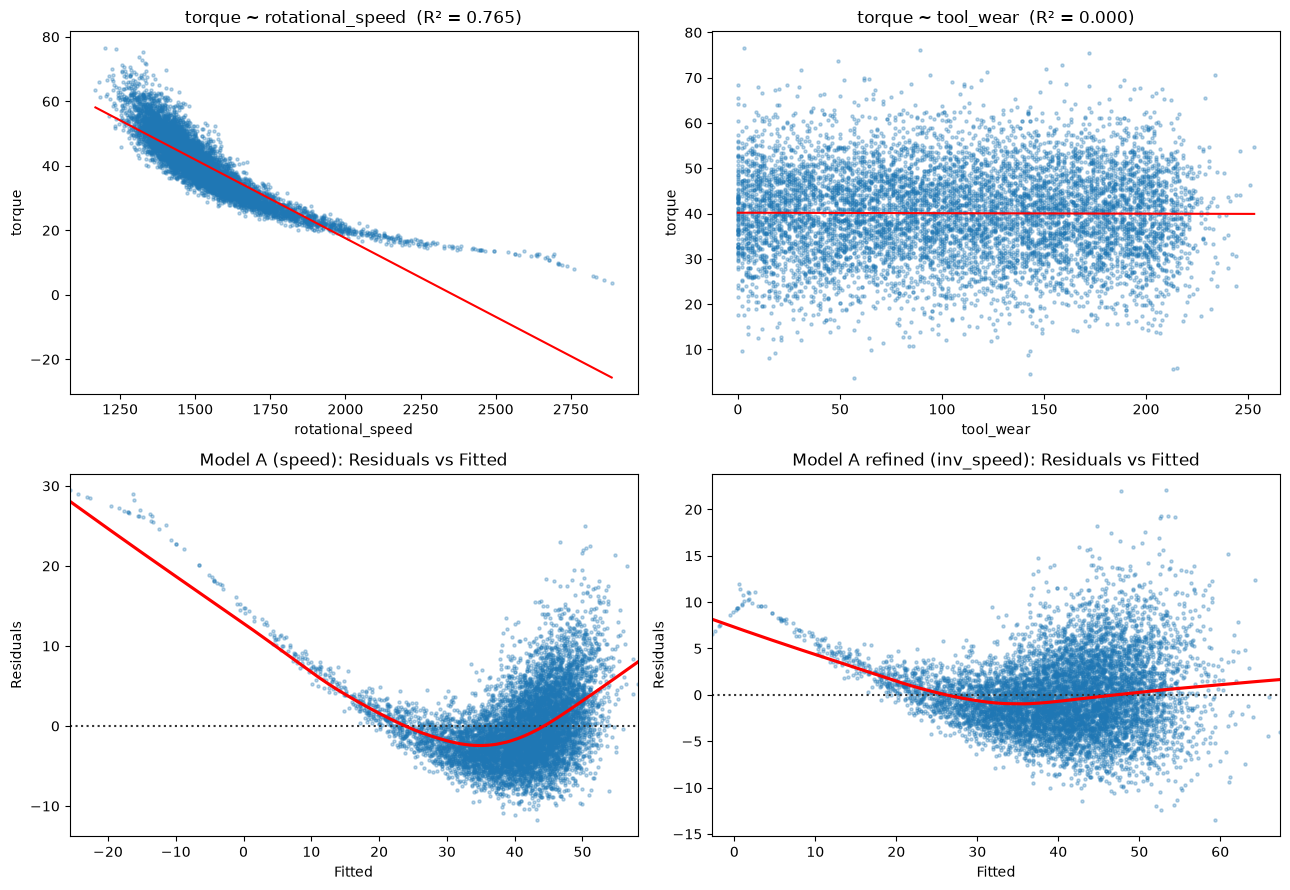

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Model A and Model B: fitted lines
for ax, model, x in [(axes[0, 0], slr_a, "rotational_speed"), (axes[0, 1], slr_b, "tool_wear")]:
    ax.scatter(train[x], train["torque"], s=5, alpha=0.3)
    x_line = np.linspace(train[x].min(), train[x].max(), 100)
    ax.plot(x_line, model.predict(pd.DataFrame({x: x_line})), color="red")
    ax.set_title(f"torque ~ {x}  (R² = {model.rsquared:.3f})")
    ax.set_xlabel(x)
    ax.set_ylabel("torque")

# Residuals vs Fitted: Model A before and after the reciprocal transformation (same as the demo)
for ax, model, title in [(axes[1, 0], slr_a, "Model A (speed)"), (axes[1, 1], slr_inv, "Model A refined (inv_speed)")]:
    sns.residplot(x=model.fittedvalues, y=model.resid, lowess=True,
                  scatter_kws={"s": 5, "alpha": 0.3}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"{title}: Residuals vs Fitted")
    ax.set_xlabel("Fitted")
    ax.set_ylabel("Residuals")

plt.tight_layout()
plt.show()


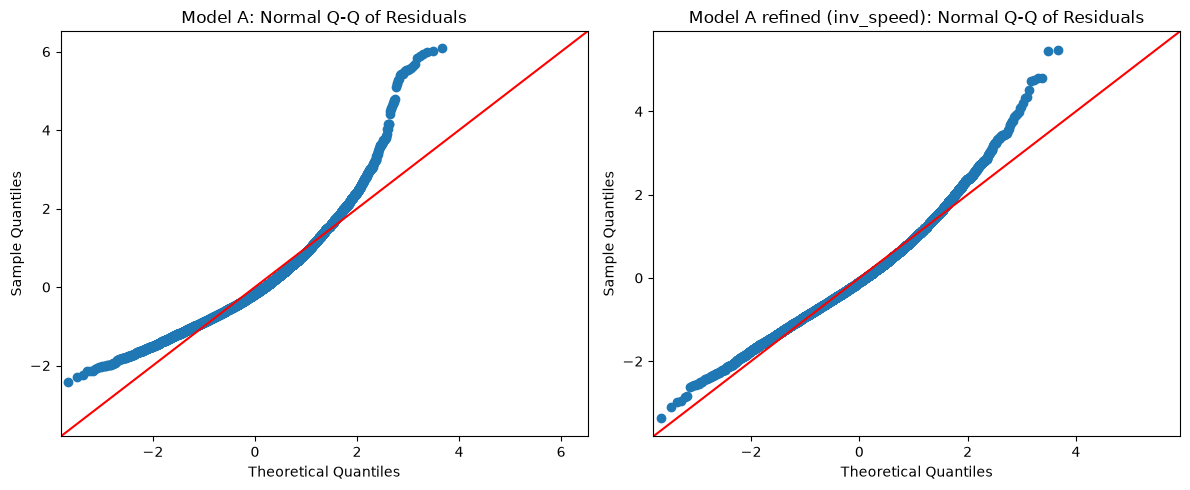

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sm.qqplot(slr_a.resid, line='45', fit=True, ax=axes[0])
axes[0].set_title("Model A: Normal Q-Q of Residuals")

sm.qqplot(slr_inv.resid, line='45', fit=True, ax=axes[1])
axes[1].set_title("Model A refined (inv_speed): Normal Q-Q of Residuals")

plt.tight_layout()
plt.show()


### Compare the SLR models


In [27]:
slr_models = {
    "A: rotational_speed": (slr_a, RMSE_trn_a, RMSE_tst_a),
    "B: tool_wear": (slr_b, RMSE_trn_b, RMSE_tst_b),
    "A refined: log_speed": (slr_log, RMSE_trn_log, RMSE_tst_log),
    "A refined: inv_speed": (slr_inv, RMSE_trn_inv, RMSE_tst_inv),
}

slr_compare = pd.DataFrame({
    "Model": list(slr_models),
    "F-stat": [m.fvalue for m, _, _ in slr_models.values()],
    "p-value (F)": [m.f_pvalue for m, _, _ in slr_models.values()],
    "R2": [m.rsquared for m, _, _ in slr_models.values()],
    "Adj R2": [m.rsquared_adj for m, _, _ in slr_models.values()],
    "Coefficient": [m.params.iloc[1] for m, _, _ in slr_models.values()],
    "AIC": [m.aic for m, _, _ in slr_models.values()],
    "Breusch-Pagan p": [het_breuschpagan(m.resid, m.model.exog)[1] for m, _, _ in slr_models.values()],
    "Residual skew": [m.resid.skew() for m, _, _ in slr_models.values()],
    "Train RMSE": [trn for _, trn, _ in slr_models.values()],
    "Test RMSE": [tst for _, _, tst in slr_models.values()],
})

slr_compare.round(3)


,Model,F-stat,p-value (F),R2,Adj R2,Coefficient,AIC,Breusch-Pagan p,Residual skew,Train RMSE,Test RMSE
0,A: rotational_speed,25981.242,0.000,0.765,0.765,-0.049,47921.162,0.000,1.314,4.835,4.789
1,B: tool_wear,0.353,0.552,0.000,-0.000,-0.001,59493.275,0.810,-0.008,9.966,9.982
2,A refined: log_speed,34301.827,0.000,0.811,0.811,-83.724,46168.896,0.122,0.920,4.333,4.311
3,A refined: inv_speed,41026.179,0.000,0.837,0.837,137.577,44988.651,0.000,0.659,4.025,4.013


### Which SLR model is better? **Model A (rotational_speed) is clearly superior.**

| Measure | Model A: rotational_speed | Model B: tool_wear | Better |
|---|---|---|---|
| F-statistic (p-value) | **25,981** (p ≈ 0) | 0.35 (p = 0.55) | A |
| R² / Adjusted R² | **0.765** | 0.000 | A |
| Slope (t-test p) | −0.0488 per rpm (p ≈ 0) | −0.001 per min (p = 0.55) | A |
| Train / Test RMSE | **4.84 / 4.79 Nm** | 9.97 / 9.98 Nm | A |
| AIC (lower is better) | **47,921** | 59,493 | A |

*Residual skew:* tool wear has the most symmetric residuals (about 0) but explains nothing, so well-behaved residuals alone
do not make a useful model.

**Walking through the evidence:**

1. **Only Model A is useful.** Its F-test and slope t-test have p ≈ 0. Model B's F-test has p = 0.55, so tool wear is not
   significantly better than predicting the average torque.
2. **Model B's RMSE (9.97) equals the standard deviation of torque (9.97).** That's the error you'd get by always predicting the
   mean, so Model B has no predictive value. Model A cuts the error in half.
3. **Both models hold up on new data:** train ≈ test RMSE for each, so neither overfits.
4. **Model A's coefficient makes sense:** each extra 100 rpm lowers torque by about **4.9 Nm** (faster = lighter load). But a straight
   line can't follow the curve. At 2,800 rpm Model A predicts **−21.6 Nm**, which is impossible.

**Refining Model A with Tukey's ladder:**

| Version of speed | R² | Test RMSE | Residual skew | Breusch-Pagan p |
|---|---|---|---|---|
| original (power 1) | 0.765 | 4.79 | 1.31 | ≈ 0 |
| log (power 0) | 0.811 | 4.31 | 0.92 | 0.12 |
| **reciprocal (power −1)** | **0.837** | **4.01** | **0.66** | ≈ 0 |

- The reciprocal explains **83.7%** of torque and cuts test error by about 16%. That's what physics predicts (torque = power ÷ speed).
  The model is torque = −50.4 + 137.6 × (1000 ÷ rpm). At 2,800 rpm it predicts about −1.3 Nm: still a little low, but much closer.
- *Residuals vs Fitted:* Model A shows a strong **U-shape** (linearity broken). The reciprocal's red line is much flatter.
- *Q-Q plot:* Model A's residuals bend far from the line (skew 1.31). The reciprocal stays much closer (skew 0.66).
- *Breusch-Pagan:* still significant for the reciprocal, so the residual spread isn't constant. That doesn't bias the coefficients or the
  RMSE; it only makes the p-values slightly optimistic (robust HC3 standard errors would fix that). The log version passes the test
  (p = 0.12) but fits worse, and for prediction accuracy matters more.
- *Note:* Model A's large condition number (1.34e+04) is not multicollinearity, because there is only one variable. It comes from speed's
  large values (around 1,500) and drops to 22 for `inv_speed`.

**Conclusion:** Model A (speed) beats Model B (tool wear) on every measure, and its reciprocal transformation is the best single-variable
model (R² 0.837, test RMSE 4.01 Nm).


## 9. Multiple Linear Regression

### Step 1: Full model with all independent variables

We start with **every independent variable that can be used**. A few variables have to be left out, otherwise the model can't
be calculated properly or it would be cheating:

| Left out | Reason |
|---|---|
| `power_w`, `power_margin_w`, `strain_minNm`, `osf_margin_minNm`, `energy_kwh`, `energy_cost_cad`, `operating_zone` | **Data leakage**: calculated from torque |
| `power_failure`, `overstrain_failure`, `machine_failure`, `n_failure_modes`, `failure_type` | **Data leakage**: defined by torque thresholds (or contain those flags) |
| `tool_wear_failure`, `heat_dissipation_failure`, `random_failure` | Outcomes only known **after** the run |
| `temp_diff` | Exactly process_temp − air_temp, so a perfect copy of two variables already in the model |
| `quality_label`, `quality_rank`, `tool_wear_added_min`, `osf_threshold_minNm` | One fixed value per product type, so perfect copies of `type` |
| `hour`, `day_of_week`, `month` | We use the simpler `shift`, `is_weekend` and `season` instead (24 hours or 12 months as straight-line numbers wouldn't make sense) |
| `hoep_price` | We use the transformed `log_hoep` instead (less skewed) |
| `timestamp` | Only a key for joining the data |

That leaves **20 independent variables** for the full model.


In [28]:
predictors = [
    "type", "air_temp", "process_temp",
    "rotational_speed", "log_speed", "inv_speed",
    "tool_wear", "tool_uses", "wear_stage",
    "shift", "is_weekend", "season",
    "outdoor_temp_c", "dew_point_c", "rel_humidity", "precip_mm", "wind_speed_kmh", "station_pressure_kpa",
    "log_hoep", "ontario_demand_mw"
]

full_formula = "torque ~ " + " + ".join(predictors)
print(full_formula)

full_model = smf.ols(full_formula, data=train).fit()

print(full_model.summary())

pred_train = full_model.predict(train)
RMSE_trn_full = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = full_model.predict(test)
RMSE_tst_full = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Full Model): {RMSE_trn_full:.2f}")
print(f"Test RMSE (Full Model): {RMSE_tst_full:.2f}")

torque ~ type + air_temp + process_temp + rotational_speed + log_speed + inv_speed + tool_wear + tool_uses + wear_stage + shift + is_weekend + season + outdoor_temp_c + dew_point_c + rel_humidity + precip_mm + wind_speed_kmh + station_pressure_kpa + log_hoep + ontario_demand_mw
                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.848
Model:                            OLS   Adj. R-squared:                  0.847
Method:                 Least Squares   F-statistic:                     1709.
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:22:54   Log-Likelihood:                -22214.
No. Observations:                8000   AIC:                         4.448e+04
Df Residuals:                    7973   BIC:                         4.467e+04
Df Model:                          26                                         
Covariance

In [29]:
# Variance Inflation Factor: how well each term can be predicted from the others (1 = independent, 10+ = serious)
def vif_table(model):
    X = model.model.exog
    names = model.model.exog_names
    vifs = [variance_inflation_factor(X, i) for i in range(X.shape[1])]
    return (pd.DataFrame({"term": names, "VIF": vifs})
              .query("term != 'Intercept'")
              .sort_values("VIF", ascending=False)
              .reset_index(drop=True))

vif_table(full_model).round(1)


,term,VIF
0,log_speed,16441.300
1,inv_speed,4685.700
2,rotational_speed,3699.000
3,dew_point_c,392.100
4,outdoor_temp_c,388.100
5,rel_humidity,46.400
6,tool_wear,27.800
7,tool_uses,20.700
8,air_temp,16.800
9,wear_stage[T.Old],11.700


**Full model results:**

- **F-statistic = 1,709 (p ≈ 0):** the model as a whole is useful.
- **R² = 0.848, Adjusted R² = 0.847:** only a little better than the best SLR (0.837), and it uses 20 variables (26 terms, because
  categorical variables become several dummy terms).
- **Train RMSE = 3.89 Nm, Test RMSE = 3.89 Nm:** train ≈ test, so there is no overfitting.

**Almost nothing is significant (p > 0.05):** all 8 external variables (6 weather variables, `log_hoep`, `ontario_demand_mw`), the
timing variables (`shift`, `is_weekend`, `season`), and `type`, both temperatures, `tool_wear`, `tool_uses` and `wear_stage`.
**Only `inv_speed` is significant.** Even `rotational_speed` has p = 0.125, because three versions of speed share the same information.

**Problem – collinearity:** the condition number is about **1.5e+08**, and the VIF table shows why:
- `log_speed` (VIF 16,441), `inv_speed` (4,686) and `rotational_speed` (3,699): three versions of one variable. They "fight" each other,
  which hides speed's significance and makes their coefficients meaningless (`log_speed` gets a positive coefficient, +19, even
  though torque falls as speed rises).
- `dew_point_c` (392) and `outdoor_temp_c` (388): dew point is physically calculated from temperature and humidity.
- `tool_wear` (28) and `tool_uses` (21): `tool_uses` is tool wear ÷ a fixed number per type.

Collinearity inflates the standard errors (the p-values), not the predictions. Backward selection should clean this up.


### Step 2: Backward Selection

We use the same `backward_selection` function as shown in class. It starts with all the variables, removes the one with the
**highest p-value**, refits the model, and repeats until every variable left has a p-value of **0.05 or lower**.

The only change: we give it just the torque column and our predictor list (instead of the whole data frame), so that it does not
pick up the leaky or duplicate variables.

In [30]:
def backward_selection(data, response):

    predictors = [col for col in data.columns if col != response]

    while True:

        formula = response + " ~ " + " + ".join(predictors)

        model = smf.ols(formula, data=data).fit()

        # Get largest p-value excluding intercept
        pvals = model.pvalues.drop("Intercept")

        worst_p = pvals.max()

        if worst_p <= 0.05:
            break

        worst_term = pvals.idxmax()

        # Handle categorical dummy variables
        base_var = worst_term.split("[")[0]

        if base_var in predictors:
            print(f"Removing: {base_var}  (p = {worst_p:.4f})")
            predictors.remove(base_var)
        else:
            print(f"Skipping term: {worst_term}")
            break

    return model

back_model = backward_selection(train[["torque"] + predictors], "torque")

print(back_model.summary())

pred_train = back_model.predict(train)
RMSE_trn_bck = np.sqrt(mean_squared_error(train["torque"], pred_train))

pred_test = back_model.predict(test)
RMSE_tst_bck = np.sqrt(mean_squared_error(test["torque"], pred_test))

print(f"Train RMSE (Backward Model): {RMSE_trn_bck:.2f}")
print(f"Test RMSE (Backward Model): {RMSE_tst_bck:.2f}")

vif_table(back_model).round(1)

Removing: type  (p = 0.8986)
Removing: process_temp  (p = 0.8393)
Removing: air_temp  (p = 0.9138)
Removing: dew_point_c  (p = 0.7545)
Removing: outdoor_temp_c  (p = 0.8363)
Removing: log_speed  (p = 0.7173)
Removing: rel_humidity  (p = 0.6723)
Removing: precip_mm  (p = 0.5053)
Removing: shift  (p = 0.4687)
Removing: season  (p = 0.4752)
Removing: station_pressure_kpa  (p = 0.5181)
Removing: tool_uses  (p = 0.3747)
Removing: wear_stage  (p = 0.2874)
Removing: tool_wear  (p = 0.9699)
Removing: is_weekend  (p = 0.2793)
Removing: wind_speed_kmh  (p = 0.1844)
Removing: log_hoep  (p = 0.2377)
Removing: ontario_demand_mw  (p = 0.3713)
                            OLS Regression Results                            
Dep. Variable:                 torque   R-squared:                       0.848
Model:                            OLS   Adj. R-squared:                  0.847
Method:                 Least Squares   F-statistic:                 2.223e+04
Date:                Thu, 26 Nov 2026   Prob (F

,term,VIF
0,rotational_speed,24.000
1,inv_speed,24.000


**Backward selection results:**

- It removed **18 variables**, one at a time, starting with `type` (p = 0.90) and ending with `ontario_demand_mw` (p = 0.37).
  **All 8 external variables were removed**, as were the timing variables, type, both temperatures, tool wear, tool uses and wear stage.
- It also removed `log_speed` (p = 0.72), which on its own fixed the worst collinearity: VIF dropped from 16,441 to **24**.
- It kept **2 variables: `rotational_speed` and `inv_speed`**, both with p ≈ 0.
- **R² = 0.848, Adjusted R² = 0.847, F = 22,226, AIC = 44,449 (the lowest of all models).**
- **Train RMSE = 3.89, Test RMSE = 3.88:** as good as the full model with 24 fewer terms. Removing those variables cost nothing.

**Why two versions of speed?** Together they work like a polynomial: they let the fitted curve bend more flexibly than `inv_speed` alone.
Because they're collinear (VIF 24), the individual coefficients shouldn't be read on their own. For example, speed's coefficient is
now **+0.028**, even though torque falls as speed rises, because `inv_speed` (+212) does most of the work. The fitted curve falls
with speed up to about **2,740 rpm** and then rises slightly. Only 6 of 10,000 runs are faster than that (checked in Step 5).

The lecture says automatic selection should be used "as a guide only", so next we test the result against alternatives.


### Step 3: Experiment with Variable Combinations

1. **Alternatives for the speed curve:** is the backward result really the best way to model the curve, or would a simpler or
   more common form do as well on the **test** set?
2. **Leakage check:** an earlier draft of this notebook used `inv_speed + power_failure + overstrain_failure` as the final model.
   We show what torque-defined variables do to the results, and why we rejected them.


In [31]:
# Alternative ways to model the speed curve, compared on the TEST set
options = {
    "Backward result": back_model.model.formula,
    "log_speed + inv_speed": "torque ~ log_speed + inv_speed",
    "speed + speed²": "torque ~ rotational_speed + I(rotational_speed**2)",
    "inv_speed only": "torque ~ inv_speed",
}
alt_rows = []
for name, formula in options.items():
    m = smf.ols(formula, data=train).fit()
    alt_rows.append({
        "Model": name,
        "Formula": formula,
        "Adj R2": m.rsquared_adj,
        "AIC": m.aic,
        "Condition No.": m.condition_number,
        "Train RMSE": np.sqrt(mean_squared_error(train["torque"], m.predict(train))),
        "Test RMSE": np.sqrt(mean_squared_error(test["torque"], m.predict(test))),
    })
pd.DataFrame(alt_rows).round(4)


,Model,Formula,Adj R2,AIC,Condition No.,Train RMSE,Test RMSE
0,Backward result,torque ~ rotational_speed + inv_speed,0.848,44449.439,180437.544,3.891,3.880
1,log_speed + inv_speed,torque ~ log_speed + inv_speed,0.847,44451.770,6156.857,3.892,3.881
2,speed + speed²,torque ~ rotational_speed + I(rotational_speed...,0.843,44687.775,97252386.723,3.950,3.932
3,inv_speed only,torque ~ inv_speed,0.837,44988.651,21.639,4.025,4.013


In [32]:
# Leakage check: what happens if variables defined by torque are added?
leak_options = {
    "Final (no leakage)": back_model.model.formula,
    "inv_speed + power_failure + overstrain_failure (earlier draft)": "torque ~ inv_speed + power_failure + overstrain_failure",
    "+ power_w": back_model.model.formula + " + power_w",
}
leak_rows = []
for name, formula in leak_options.items():
    m = smf.ols(formula, data=train).fit()
    leak_rows.append({
        "Model": name,
        "R2": m.rsquared,
        "Train RMSE": np.sqrt(mean_squared_error(train["torque"], m.predict(train))),
        "Test RMSE": np.sqrt(mean_squared_error(test["torque"], m.predict(test))),
    })
pd.DataFrame(leak_rows).round(4)


,Model,R2,Train RMSE,Test RMSE
0,Final (no leakage),0.848,3.891,3.880
1,inv_speed + power_failure + overstrain_failure...,0.855,3.798,3.768
2,+ power_w,0.999,0.381,0.378


### Step 4: Compare all Models

In [33]:
models = {
    "SLR A (rotational_speed)": (slr_a, RMSE_trn_a, RMSE_tst_a),
    "SLR B (tool_wear)": (slr_b, RMSE_trn_b, RMSE_tst_b),
    "SLR A refined (inv_speed)": (slr_inv, RMSE_trn_inv, RMSE_tst_inv),
    "Full": (full_model, RMSE_trn_full, RMSE_tst_full),
    "Backward = Final": (back_model, RMSE_trn_bck, RMSE_tst_bck),
}

comparison = pd.DataFrame({
    "Model": list(models.keys()),
    "No. of terms": [m.df_model for m, _, _ in models.values()],
    "F-stat": [m.fvalue for m, _, _ in models.values()],
    "R2": [m.rsquared for m, _, _ in models.values()],
    "Adj R2": [m.rsquared_adj for m, _, _ in models.values()],
    "AIC": [m.aic for m, _, _ in models.values()],
    "Condition No.": [m.condition_number for m, _, _ in models.values()],
    "Train RMSE": [trn for _, trn, _ in models.values()],
    "Test RMSE": [tst for _, _, tst in models.values()]
})

comparison.round(3)


,Model,No. of terms,F-stat,R2,Adj R2,AIC,Condition No.,Train RMSE,Test RMSE
0,SLR A (rotational_speed),1.000,25981.242,0.765,0.765,47921.162,13413.755,4.835,4.789
1,SLR B (tool_wear),1.000,0.353,0.000,-0.000,59493.275,247.190,9.966,9.982
2,SLR A refined (inv_speed),1.000,41026.179,0.837,0.837,44988.651,21.639,4.025,4.013
3,Full,26.000,1708.546,0.848,0.847,44481.594,149931623.375,3.888,3.887
4,Backward = Final,2.000,22225.969,0.848,0.847,44449.439,180437.544,3.891,3.880


### Step 5: Check Assumptions of the Final Model

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         -142.7826      3.928    -36.347      0.000    -150.483    -135.082
rotational_speed     0.0282      0.001     23.659      0.000       0.026       0.031
inv_speed          212.0542      3.216     65.942      0.000     205.750     218.358
Breusch-Pagan p = 1.28e-150 | residual skew = 0.53


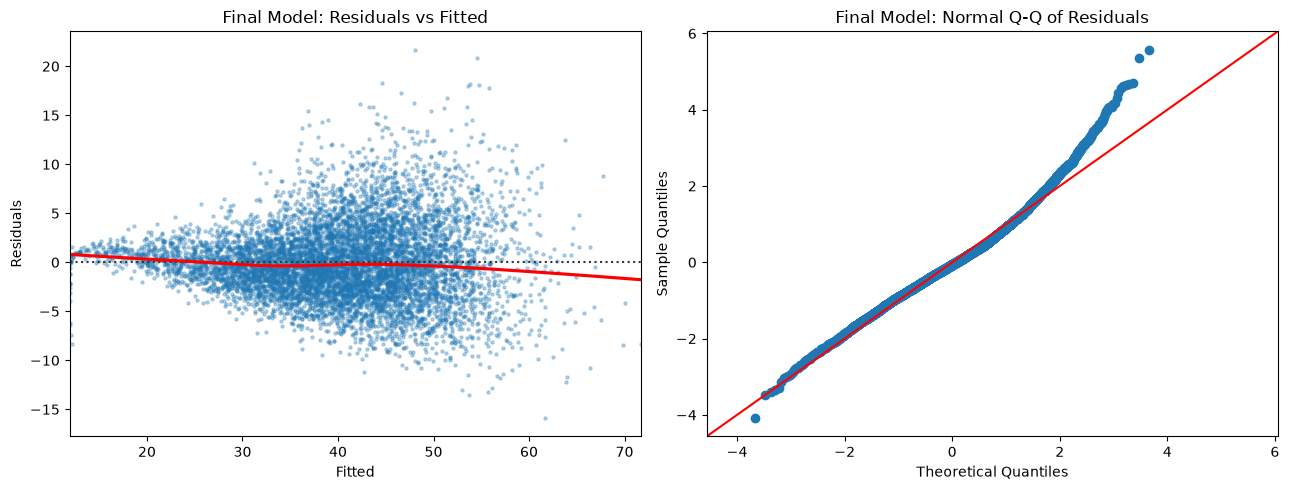

In [34]:
final_model = back_model
print(final_model.summary().tables[1])
print(f"Breusch-Pagan p = {het_breuschpagan(final_model.resid, final_model.model.exog)[1]:.2e} | residual skew = {final_model.resid.skew():.2f}")


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.residplot(x=final_model.fittedvalues, y=final_model.resid, lowess=True,
              scatter_kws={"s": 5, "alpha": 0.3}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_xlabel("Fitted")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Final Model: Residuals vs Fitted")

sm.qqplot(final_model.resid, line='45', fit=True, ax=axes[1])
axes[1].set_title("Final Model: Normal Q-Q of Residuals")

plt.tight_layout()
plt.show()

In [35]:
# Unequal residual spread: recheck significance with robust (HC3) standard errors
robust = final_model.get_robustcov_results(cov_type="HC3")
display(pd.DataFrame({"coef": final_model.params.values,
                      "std err (usual)": final_model.bse.values,
                      "std err (HC3)": robust.bse,
                      "p-value (HC3)": robust.pvalues},
                     index=final_model.params.index))

,coef,std err (usual),std err (HC3),p-value (HC3)
Intercept,-142.783,3.928,4.036,0.000
rotational_speed,0.028,0.001,0.001,0.000
inv_speed,212.054,3.216,3.420,0.000


**Does the model work at every speed?** We compare the average actual and predicted torque in speed bands (training data).

In [36]:
# Compare actual and predicted torque across the speed range
speed_band = pd.cut(train["rotational_speed"], bins=[0, 1300, 1500, 2000, 2400, 2700, 3000])
band_check = pd.DataFrame({"speed_band": speed_band,
                           "actual": train["torque"],
                           "predicted": final_model.predict(train)})
display(band_check.groupby("speed_band", observed=True).agg(
    runs=("actual", "size"),
    mean_actual=("actual", "mean"),
    mean_predicted=("predicted", "mean")).round(2))

# Speed where the slope of the fitted curve becomes zero
turning = np.sqrt(1000 * final_model.params["inv_speed"] / final_model.params["rotational_speed"])
print(f"Fitted curve stops falling at about {turning:.0f} rpm")
print("Runs above that speed:", (df_clean["rotational_speed"] > turning).sum())

,runs,mean_actual,mean_predicted
speed_band,,,
"(0, 1300]",173,59.650,60.140
"(1300, 1500]",3767,46.980,46.850
"(1500, 2000]",3883,33.580,33.710
"(2000, 2400]",140,17.800,16.900
"(2400, 2700]",27,12.940,12.390
"(2700, 3000]",10,7.510,11.950


Fitted curve stops falling at about 2742 rpm
Runs above that speed: 6


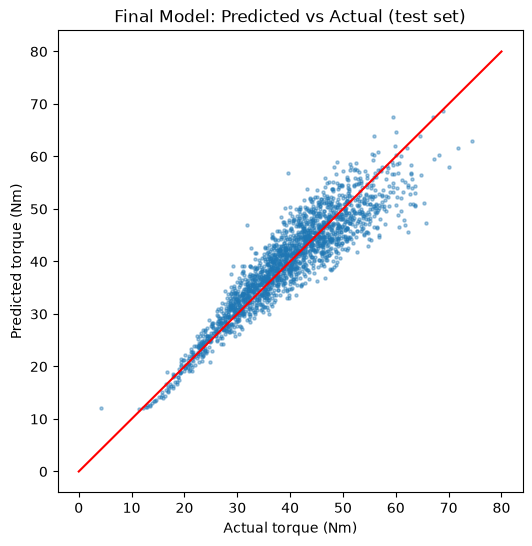

In [37]:
# Predicted vs actual torque on the TEST set
pred_test_final = final_model.predict(test)

plt.figure(figsize=(6, 6))
plt.scatter(test["torque"], pred_test_final, s=5, alpha=0.4)
plt.plot([0, 80], [0, 80], color="red")
plt.xlabel("Actual torque (Nm)")
plt.ylabel("Predicted torque (Nm)")
plt.title("Final Model: Predicted vs Actual (test set)")
plt.show()

### Step 6: Using the model to spot unusual runs

Our business question was whether torque far from the expected value is a warning sign. We flag a test run when its
error is more than 2 residual standard deviations (measured on the training data), then compare failure rates.
The failure flags are **not** model inputs. We only use them afterwards to check the result.

In [38]:
# Flag test runs whose torque is far from what the model expects
limit = 2 * np.sqrt(final_model.mse_resid)        # from the training data
residual = test["torque"] - final_model.predict(test)

group = np.select([residual > limit, residual < -limit],
                  ["Much higher than expected", "Much lower than expected"],
                  default="As expected")

print(f"Limit: {limit:.2f} Nm")
flag_table = test.groupby(group)["machine_failure"].agg(runs="size", failures="sum", failure_rate="mean")
flag_table["failure_rate"] *= 100      # percent
display(flag_table.round(2))

# Which failure types are in each group?
flags = ["tool_wear_failure", "heat_dissipation_failure", "power_failure", "overstrain_failure", "random_failure"]
display(test.groupby(group)[flags].sum().T)

Limit: 7.78 Nm


,runs,failures,failure_rate
As expected,1899,52,2.740
Much higher than expected,60,18,30.000
Much lower than expected,41,2,4.880


,As expected,Much higher than expected,Much lower than expected
tool_wear_failure,10,1,0
heat_dissipation_failure,19,1,1
power_failure,6,13,1
overstrain_failure,13,8,0
random_failure,1,0,0


**What we found:** runs with much higher torque than expected failed about **11 times** as often as normal runs
(**30.0%** vs **2.7%**). This supports using the model as a warning signal.

It has clear limits:

- It flags only **18 of the 72** test failures, and 42 of the 60 flagged runs did not fail.
- It mainly catches power failures (13 of 20) and overstrain failures (8 of 21). This is expected, because both are
  defined using torque.
- It catches almost no tool wear (1 of 11) or heat dissipation failures (1 of 21).
- Runs with much *lower* torque than expected failed 4.9% of the time (2 of 41), too few to draw a conclusion.

It is a first check, not a failure predictor.

### Our final model: torque ~ rotational_speed + inv_speed

**torque = −142.78 + 0.0282 × rotational_speed + 212.05 × (1000 ÷ rotational_speed)**

**Evidence for choosing it:**

| Option | Adj R² | Test RMSE | Condition no. |
|---|---|---|---|
| **speed + inv_speed (backward result)** | **0.848** | **3.880** | 180,000 |
| log_speed + inv_speed | 0.847 | 3.881 | 6,200 |
| speed + speed² | 0.843 | 3.932 | 97,000,000 |
| inv_speed only | 0.837 | 4.013 | 22 |
| Full model (26 terms) | 0.847 | 3.887 | 150,000,000 |

1. **It's what backward selection chose, and it holds up on unseen data:** it has the best test RMSE of the alternatives.
   `log_speed + inv_speed` is practically tied (3.881). Either is defensible, and we keep the one selection chose.
2. **Occam's Razor:** it matches the 26-term full model (test RMSE 3.887) with only **2 terms**.
3. **Every term is highly significant** (p ≈ 0), and its F-statistic (22,226) is the highest of the multi-variable models.
4. **It follows the physics:** torque = power ÷ speed, so torque should fall as 1 ÷ speed. The extra speed term adjusts the curve's shape.
5. **No overfitting:** train RMSE (3.89) ≈ test RMSE (3.88).
6. **Compared with the best SLR (inv_speed only):** test RMSE improves from 4.01 to **3.88 Nm**.

**Why we rejected the failure flags (leakage check):**

| Model | R² | Test RMSE |
|---|---|---|
| Final (no leakage) | 0.848 | 3.880 |
| inv_speed + power_failure + overstrain_failure (earlier draft) | 0.855 | 3.768 |
| + power_w | **0.999** | **0.378** |

Adding `power_w` gives an almost perfect R², because power **is** torque × speed. The failure flags are the same trap in a milder form:
`power_failure` is power outside 3,500–9,000 W and `overstrain_failure` is wear × torque above a limit (both proved by our rule check).
Their extra 0.11 Nm of accuracy comes from torque information hidden inside them, and they're only known after a run.

**Assumption checks:**

- *Residuals vs Fitted:* the red line is close to flat for most of the data, with a small bend at the far left (the few very-high-speed,
  low-torque runs).
- *Q-Q plot:* the residuals follow the line well, with a slightly heavier upper tail (skew 0.53).
- *Breusch-Pagan:* p ≈ 0, so the residual spread isn't constant. This doesn't bias the coefficients, but it makes the usual
  standard errors unreliable. We rechecked with robust (HC3) standard errors: they barely change (for example `inv_speed`
  3.22 → 3.42) and every term still has p ≈ 0, so our conclusions hold.
- *VIF = 24* for the two speed terms: expected for two forms of one variable. It affects the coefficients' precision, not the predictions.
- *Speed bands:* the average error is under 1 Nm in every band up to 2,700 rpm. In the 2,700–3,000 rpm band
  (10 training runs) actual torque averages **7.51 Nm** but the model predicts **11.95 Nm**.
- *Predicted vs Actual (test set):* the points sit close to the red line over most of the range. At very high speed
  (above 2,700 rpm) the model over-predicts torque by about 4 Nm on average, so it should not be trusted there.


## 10. Final Summary

1. **Data:** we added the **product type specifications** and **failure rules** from the official documentation (which recreated the
   HDF, PWF and OSF flags exactly). We also merged three **separate public datasets** on an hourly timestamp: Environment Canada weather
   for Kitchener-Waterloo, and IESO electricity price and Ontario demand. Every merge was validated as one-to-one. Finally, we added our
   **Workshop B operating zones**. The study file now has **45 usable variables**, and all categorical variables are converted.
2. **Transformations:** Tukey's ladder (log and reciprocal) reduced the skew in rotational speed and electricity price, and
   missing weather hours were filled by interpolation. More importantly, `inv_speed`
   (1000 ÷ rpm) straightened out the curved relationship with torque, as the physics (torque = power ÷ speed) suggests.
3. **Split:** 80/20 train/test. The KS and chi-square tests showed the two sets are comparable. The small differences are a slightly
   higher failure rate in the test set (3.6% vs 3.3%), the electricity price spikes falling mostly in the training set, and small
   expected counts for the rarest failure types.
4. **SLR:** rotational speed (R² 0.765, test RMSE 4.79) beat tool wear (R² ≈ 0, RMSE = torque's standard deviation) on every measure.
   Refining speed with Tukey's ladder (inv_speed) raised R² to 0.837 and cut test RMSE to 4.01 Nm.
5. **MLR:** from 20 legitimate predictors, backward selection kept only **rotational_speed + inv_speed** (R² 0.848, test RMSE 3.88 Nm),
   matching the 26-term full model with 2 terms. Torque-defined variables (failure flags, power) were excluded as leakage. They would
   make the model look better (up to R² 0.999), but only because they contain the answer.
6. **The external data didn't help predict torque.** Backward selection removed all 8 weather and electricity variables. This makes
   sense, because the sanity check showed the AI4I data doesn't react to real outside conditions. The new variables are still useful
   for other questions in our term project, such as the energy cost of each run.
7. **What this means for our term project:** speed explains about 85% of the torque. The rest is random variation in the simulation,
   which no other variable can explain. A run whose real torque is well above what the model expects is a warning sign worth investigating.
   We tested this on the test set (Section 9, Step 6): runs far above the expected torque failed **30.0%** of the time,
   against **2.7%** for normal runs. The check only catches 18 of the 72 failures, mostly power and overstrain, so it
   is a first warning and not a failure predictor.